# Figure 2

Assembles the panels at their final size; run from this directory. The analyses keep their own figures in
`experiments/analyses/phylogeny/`; this notebook only places them, with a heading that names what each panel shows.
Layout: a, b and, in the right column, c above d.

- **a**: *Filoviridae* glycoprotein (GP). `filoviridae_gp_species_trees` (representative sequences, one per species) beside
  `filoviridae_gp_full_trees` (all sequences), ESM3Di above ProstT5, written by `filoviridae_trees.ipynb`. Vector graphics.
- **b**: *Flaviviridae* E2 glycoprotein. `flaviviridae_e2_trees`, written by `flaviviridae_trees.ipynb`. Vector graphics.
- **c**: the metagenomic tree coloured by bacterial host class, from `../experiments/analyses/phylogeny/metagenomic_trees/`
  (`metagenomic_trees/figures/metagenomic_protein_cluster_tree.png`). The legend repeats the entries and colours of
  `metagenomic_trees/figures/metagenomic_protein_cluster_legend.svg` in the style of panels a and b, as close to the tree as its white space
  allows. The largest tree is chosen that leaves room for it.
- **d**: reserved for the polyprotein cleavage results (`SHOW_D_PLACEHOLDER` draws or removes the empty frame).

Writes `figures/figure2.pdf` and `figures/figure2.png`.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from PIL import Image
from pypdf import PdfReader, PdfWriter, Transformation

sys.path.insert(0, "../benchmarks")  # holds the shared figure style
sys.path.insert(0, "../experiments/analyses/phylogeny/shared")  # the legends of panels a and b
from pub_style import MM, MUTED_TEXT, WIDTH_DOUBLE, use_pub_style
from tree_plot import INK_GRID_MM, closest_spot, cropped_tree_image, draw_legend, legend_geometry, mm_canvas, rich_text

use_pub_style()
Image.MAX_IMAGE_PIXELS = None
OUT_DIR = Path("figures")
PHYLOGENY = Path("../experiments/analyses/phylogeny")
DPI = 600
POINT_MM = 25.4 / 72

BOLD, BOLD_ITALIC = dict(fontweight="bold"), dict(fontweight="bold", fontstyle="italic")
HEADER_MM = 5        # above a panel, for the letter and heading
HEADINGS = {"a": [("Filoviridae", BOLD_ITALIC), (" glycoprotein", BOLD)],
            "b": [("Flaviviridae", BOLD_ITALIC), (" E2 glycoprotein", BOLD)],
            "c": [("Metagenomic tree: bacterial host class", BOLD)],
            "d": [("Polyprotein cleavage", BOLD)]}
PANEL_D_IMAGE = Path("../experiments/analyses/polyprotein_cut/results/esm3di_vs_esmpp_standardised")\
                / "roc_curves_by_genus.png"   # None -> keep the reserved frame
SHOW_D_PLACEHOLDER = PANEL_D_IMAGE is None   # the empty frame that reserves panel d
# Where the values of the ROC AUC table of panel d are in that image, in points of its SVG: the column centres and
# the baseline of each row. The image is not drawn by a script of this repository, so the best value of each row
# (from summary.csv) is redrawn in bold here, and the model names of the header in regular type, so that bold in
# the table only marks the best value.
D_HEADER_TOP, D_HEADER_BOTTOM, D_HEADER_BASELINE = 130.576, 146.951, 140.374
# Vector panels, left to right; c and d follow in a column at their right
VECTOR_PANELS = [("a", PHYLOGENY / "filoviridae/figures/filoviridae_gp_species_trees"),
                 (None, PHYLOGENY / "filoviridae/figures/filoviridae_gp_full_trees"),
                 ("b", PHYLOGENY / "flaviviridae/figures/flaviviridae_e2_trees")]
HOST_LEGEND_ROW_MM = 1.7   # tighter than the other legends; the text stays at the smallest accepted size
HOST_TREE = PHYLOGENY / "metagenomic_trees/figures/metagenomic_protein_cluster_tree.png"
HOST_LEGEND = [("Gammaproteobacteria", "#0072B2"), ("Bacteroidia", "#D55E00"), ("Clostridia", "#009E73"),
               ("Bacilli", "#CC79A7"), ("Actinomycetes", "#E69F00"), ("Alphaproteobacteria", "#56B4E9"),
               ("Verrucomicrobiia", "#332288"), ("Terriglobia", "#882255"), ("Negativicutes", "#44AA99"),
               ("Cyanobacteriia", "#AA4499"), ("Others", "#8C8C8C"), ("Unassigned", "#CCCCCC")]

pages = [PdfReader(path.with_suffix(".pdf")).pages[0] for _, path in VECTOR_PANELS]
widths = [float(page.mediabox.width) * POINT_MM for page in pages]
WIDTH_MM = WIDTH_DOUBLE / MM
HEIGHT_MM = HEADER_MM + max(float(page.mediabox.height) * POINT_MM for page in pages)
PANEL_OVERLAP_MM = (0, 3, 0)         # how far a panel reaches over the one before: the species names and tips do not meet
offsets = np.cumsum([0, *widths[:-1]]) - np.cumsum(PANEL_OVERLAP_MM)
COLUMN_X_MM = offsets[-1] + widths[-1]   # c and d fill the rest of the width
COLUMN_MM = WIDTH_MM - COLUMN_X_MM
ROW_MM = HEIGHT_MM / 2               # c and d have the same height
AREA_MM = ROW_MM - HEADER_MM         # of c and d, below their heading


c: tree 51 mm, legend covers 0.0 mm2 of ink
d: cut-site panel 54 x 54 mm in a 65 x 54 mm area


183 x 121 mm; columns [27, 37, 55, 67] mm wide


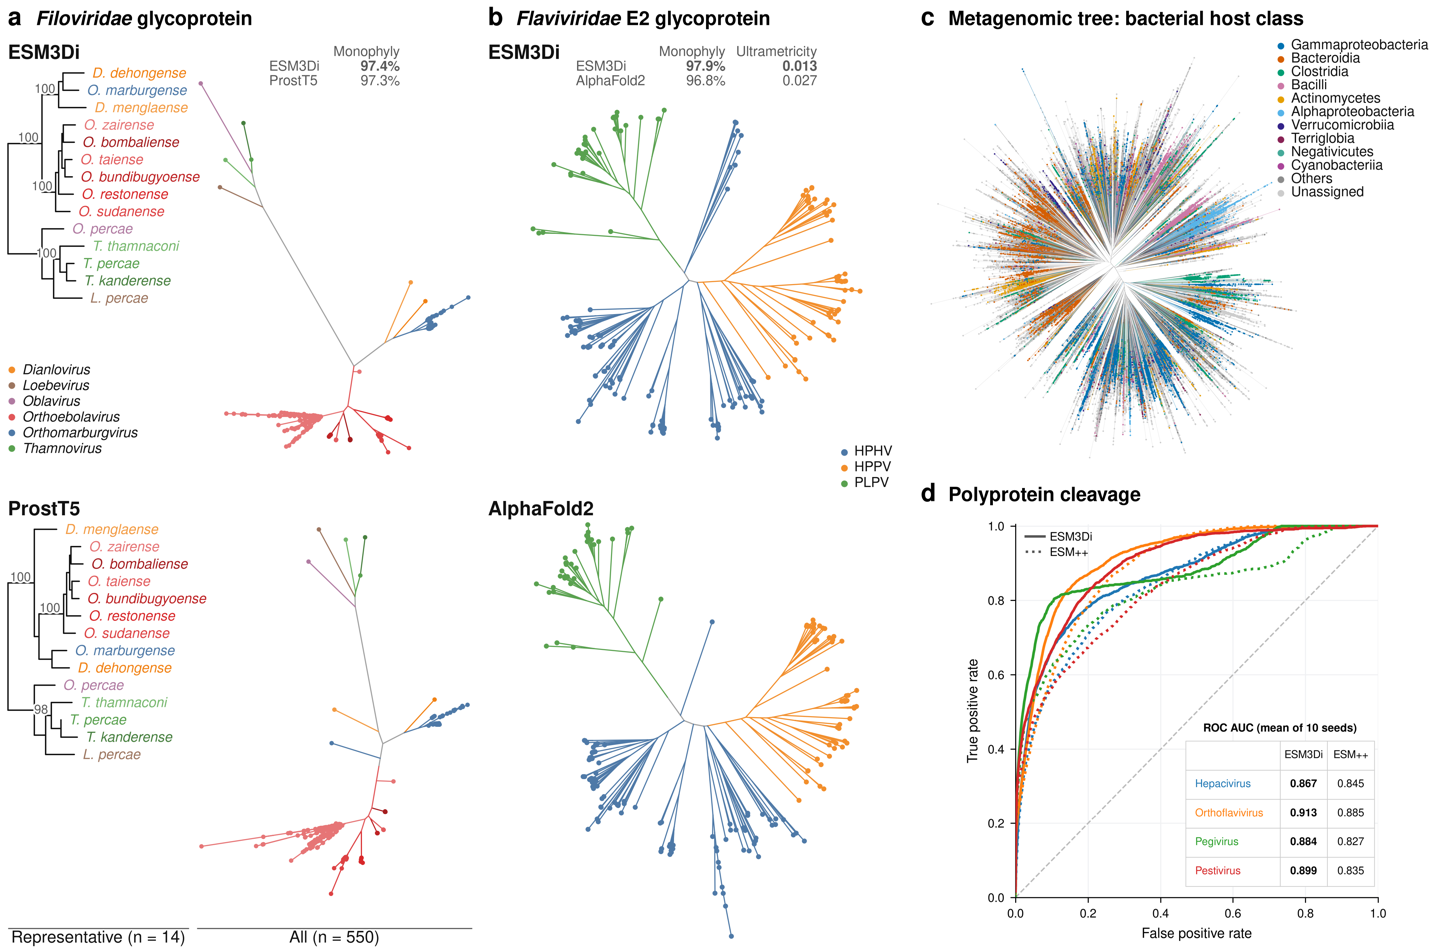

In [2]:
def best_placement(mask, legend_width, legend_height):
    """The largest tree at the left of panel c, vertically centred, with white space for the legend.

    mask: where the image has ink, square. Returns ink covered, tree size, tree top and legend position (mm in the panel).
    """
    columns, rows = int(COLUMN_MM / INK_GRID_MM), int(AREA_MM / INK_GRID_MM)
    best = None
    for size in np.arange(min(COLUMN_MM, AREA_MM) - 0.5, 39, -0.5):
        cells = int(size / INK_GRID_MM)
        scaled = mask[np.ix_(*[np.arange(cells) * mask.shape[0] // cells] * 2)]
        top = (AREA_MM - size) / 2
        grid = np.zeros((rows, columns), bool)
        y = round(top / INK_GRID_MM)
        grid[y:y + cells, :cells] = scaled
        spot, ink = closest_spot(grid, legend_width, legend_height)
        if best is None or ink < best[0]:
            best = ink, size, top, spot
        if ink <= ALLOWED_INK_MM2:
            break
    return best


def heading(canvas, letter, x, top):
    """The panel letter and, on its baseline, what the panel shows."""
    canvas.text(x + 1, top + 3.2, letter, fontsize=9, fontweight="bold", va="baseline")
    rich_text(canvas, x + 4.5, top + 3.2, HEADINGS[letter], fontsize=7, va="baseline")


ALLOWED_INK_MM2 = 0.0   # ink a legend may cover (with its margin): none, so that no tip reads as a legend marker

# Everything except the vector panels: the headings and the right column
fig = plt.figure(figsize=(WIDTH_MM * MM, HEIGHT_MM * MM))
canvas = mm_canvas(fig, WIDTH_MM, HEIGHT_MM)
for (letter, _), x in zip(VECTOR_PANELS, offsets):
    if letter:
        heading(canvas, letter, x, 0)
heading(canvas, "c", COLUMN_X_MM, 0)
heading(canvas, "d", COLUMN_X_MM, ROW_MM)

# Panel c
image = cropped_tree_image(HOST_TREE)
ink = np.asarray(image.resize((480, 480), Image.Resampling.BOX)).min(axis=2) < 250
blocks = [(None, [entry], False) for entry in HOST_LEGEND]
_, _, legend_width, legend_height = legend_geometry(blocks, 1, row_mm=HOST_LEGEND_ROW_MM)
covered, size, top, spot = best_placement(ink, legend_width, legend_height)
pixels = round(size * MM * DPI)
ax = fig.add_axes((COLUMN_X_MM / WIDTH_MM, 1 - (HEADER_MM + top + size) / HEIGHT_MM, size / WIDTH_MM, size / HEIGHT_MM))
ax.imshow(np.asarray(image.resize((pixels, pixels), Image.Resampling.LANCZOS)), interpolation="none")
ax.set_axis_off()
draw_legend(canvas, blocks, COLUMN_X_MM + spot[0], HEADER_MM + spot[1], row_mm=HOST_LEGEND_ROW_MM)
print(f"c: tree {size:.0f} mm, legend covers {covered:.1f} mm2 of ink")

# Panel d: the cut-site ROC panel. It is rendered by
# experiments/analyses/polyprotein_cut/scripts/make_paper_figures.py at exactly this size,
# in the shared publication style, with the ESM3Di values already bold - so it is placed
# as-is, with no redrawing of its text here.
if PANEL_D_IMAGE is not None:
    d_image = Image.open(PANEL_D_IMAGE).convert("RGB")
    box_w, box_h = COLUMN_MM - 2, AREA_MM - 1.5
    scale = min(box_w / d_image.width, box_h / d_image.height)
    draw_w, draw_h = d_image.width * scale, d_image.height * scale
    d_x = COLUMN_X_MM + 1 + (box_w - draw_w) / 2
    d_y = ROW_MM + HEADER_MM + 0.5 + (box_h - draw_h) / 2
    ax = fig.add_axes((d_x / WIDTH_MM, 1 - (d_y + draw_h) / HEIGHT_MM,
                       draw_w / WIDTH_MM, draw_h / HEIGHT_MM))
    ax.imshow(np.asarray(d_image.resize((round(draw_w * MM * DPI), round(draw_h * MM * DPI)),
                                        Image.Resampling.LANCZOS)), interpolation="none")
    ax.set_axis_off()
    print(f"d: cut-site panel {draw_w:.0f} x {draw_h:.0f} mm in a {box_w:.0f} x {box_h:.0f} mm area")

if SHOW_D_PLACEHOLDER:
    canvas.add_patch(FancyBboxPatch((COLUMN_X_MM + 1, ROW_MM + HEADER_MM + 0.5), COLUMN_MM - 2, AREA_MM - 1.5,
                                    boxstyle="round,pad=0,rounding_size=1", fill=False, ec="0.75", lw=0.6, ls=(0, (4, 3))))
    canvas.text(COLUMN_X_MM + COLUMN_MM / 2, ROW_MM + HEADER_MM + AREA_MM / 2, "Reserved for polyprotein cleavage results", ha="center",
                va="center", fontsize=6, color=MUTED_TEXT)
with plt.rc_context({"savefig.bbox": "standard"}):
    fig.savefig(OUT_DIR / "figure2.png", dpi=DPI)
    fig.savefig(OUT_DIR / "figure2.pdf")
plt.close(fig)

# PDF: panels a and b stay vector graphics
writer = PdfWriter(clone_from=OUT_DIR / "figure2.pdf")
for page, x in zip(pages, offsets):
    bottom = HEIGHT_MM - HEADER_MM - float(page.mediabox.height) * POINT_MM
    writer.pages[0].merge_transformed_page(page, Transformation().translate(x / POINT_MM, bottom / POINT_MM))
writer.write(OUT_DIR / "figure2.pdf")

# PNG: the same panels from their 600 dpi files
image = Image.open(OUT_DIR / "figure2.png").convert("RGB")
for (_, path), x in zip(VECTOR_PANELS, offsets):
    panel = Image.open(path.with_suffix(".png")).convert("RGBA")
    image.paste(panel, (round(x * MM * DPI), round(HEADER_MM * MM * DPI)), panel)
image.save(OUT_DIR / "figure2.png", dpi=(DPI, DPI))

print(f"{WIDTH_MM:.0f} x {HEIGHT_MM:.0f} mm; columns {[round(w) for w in (*widths, COLUMN_MM)]} mm wide")
image.resize((image.width // 3, image.height // 3))
